# Traces

In [ ]:
import os
import numpy as np
from matplotlib import pyplot as plt
import torch
import random


save_plots = False
pad_inches = 0.01
clip_on = False

num_points = 1000
spike_threshold = 0.997
spike_height = 0.9
spike_color = "black"

beta_trace = 0.99
trace_color = "orange"

slow_beta = 0.9945
fast_beta = 0.99
slow_gain = 1.5
fast_gain = 2.5
slow_trace_color = "blue"
fast_trace_color = "green"


if save_plots:
    dir_path = "plots/figure_1/"
    os.makedirs(dir_path, exist_ok=True)


def trace_over(x:np.ndarray, beta:float) -> np.ndarray:
    y = []
    buff = 0
    for value in x:
        buff = beta * buff + value
        y.append(buff)
    y = np.array(y)
    return y


def create_fig_ax(x:np.ndarray, pad_inches:float=0.) -> tuple[plt.Figure, plt.Axes]:
    min = np.min(x)
    max = np.max(x)
    pads = (2 * pad_inches)
    size = max - min

    width = 3.5
    height = (size + pads) / 2.54
    fig = plt.Figure((width, height))

    bottom_ratio = pad_inches / (size + pads)
    height_ratio = size / (size + pads)
    ax = fig.add_axes([0, bottom_ratio, 1, height_ratio])

    ax.set_ylim(min, max)
    ax.set_xlim(0, len(x)-1)
    
    ax.axis("off")
    return fig, ax


plt.show()

np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

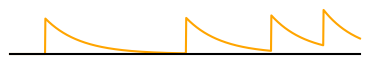

In [ ]:
np.random.seed(8)
x = (np.random.rand(num_points) > spike_threshold).astype(int) * spike_height

e = trace_over(x, beta=beta_trace)
fig, ax = create_fig_ax(e)

ax.plot(e, c=trace_color, clip_on=clip_on)
ax.plot(np.zeros_like(e), c="black", clip_on=clip_on)

if save_plots:
    fig.savefig(dir_path + "trace1.svg", bbox_inches="tight", pad_inches=pad_inches)
fig

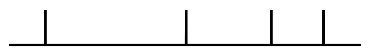

In [3]:
fig, ax = create_fig_ax(x)
ax.plot(x, c=spike_color)
ax.plot(np.zeros_like(x), c="black", clip_on=clip_on)

if save_plots:
    fig.savefig(dir_path + "spikes1.svg", bbox_inches="tight", pad_inches=pad_inches)
fig

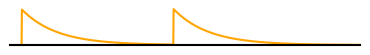

In [ ]:
np.random.seed(41)
x = (np.random.rand(num_points) > spike_threshold).astype(int) * spike_height

e = trace_over(x, beta=beta_trace)
fig, ax = create_fig_ax(e)

ax.plot(e, c=trace_color, clip_on=clip_on)
ax.plot(np.zeros_like(e), c="black", clip_on=False)

if save_plots:
    fig.savefig(dir_path + "trace2.svg", bbox_inches="tight", pad_inches=pad_inches)
fig

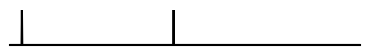

In [5]:
fig, ax = create_fig_ax(x)
ax.plot(x, c=spike_color)
ax.plot(np.zeros_like(x), c="black", clip_on=clip_on)

if save_plots:
    fig.savefig(dir_path + "spikes2.svg", bbox_inches="tight", pad_inches=pad_inches)
fig

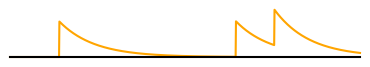

In [ ]:
np.random.seed(23)
x = (np.random.rand(num_points) > spike_threshold).astype(int) * spike_height

e = trace_over(x, beta=beta_trace)
fig, ax = create_fig_ax(e)

ax.plot(e, c=trace_color, clip_on=clip_on)
ax.plot(np.zeros_like(e), c="black", clip_on=clip_on)

if save_plots:
    fig.savefig(dir_path + "trace3.svg", bbox_inches="tight", pad_inches=pad_inches)
fig

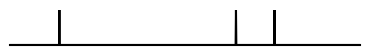

In [7]:
fig, ax = create_fig_ax(x)
ax.plot(x, c=spike_color)
ax.plot(np.zeros_like(x), c="black", clip_on=clip_on)

if save_plots:
    fig.savefig(dir_path + "spikes3.svg", bbox_inches="tight", pad_inches=pad_inches)
fig

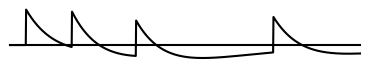

In [ ]:
np.random.seed(18)
x = (np.random.rand(num_points) > spike_threshold).astype(int) * spike_height

gs = trace_over(x, beta=slow_beta)
gf = trace_over(x, beta=fast_beta)
dg = fast_gain * gf - slow_gain * gs

fig, ax = create_fig_ax(dg, pad_inches=0.03)
ax.plot(dg, c="black", clip_on=clip_on)
ax.plot(np.zeros_like(dg), c="black", clip_on=clip_on)

if save_plots:
    fig.savefig(dir_path + "trace_diff.svg")
fig

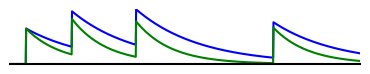

In [9]:
fig, ax = create_fig_ax(gs, pad_inches=0.2)
ax.plot(gs, c=slow_trace_color)
ax.plot(gf, c=fast_trace_color)
ax.plot(np.zeros_like(gs), c="black", clip_on=clip_on)

if save_plots:
    fig.savefig(dir_path + "traces_sf.svg", bbox_inches="tight", pad_inches=pad_inches)
fig

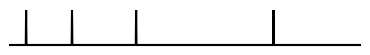

In [10]:
fig, ax = create_fig_ax(x)
ax.plot(x, c=spike_color)
ax.plot(np.zeros_like(x), c="black", clip_on=clip_on)

if save_plots:
    fig.savefig(dir_path + "spikes_out.svg", bbox_inches="tight", pad_inches=pad_inches)
fig